# Generador de datos sintéticos — Línea Madrid–Barcelona

Este cuaderno genera un conjunto de datos sintético y **reproducible** para
plantear un nuevo enfoque del problema de optimización de horarios (CRAFT).
A diferencia del generador de `robin` (cuaderno `1.0-Supply_Generator`), aquí
la generación está desacoplada del simulador y produce **dos archivos
independientes** en `data/synthetic/`:

| Archivo | Contenido |
|---|---|
| `timetable.yaml` | **Horarios en formato robin**: estaciones, corredor, franjas horarias, líneas (una por servicio, con tiempos relativos), material rodante, asientos, RUs y servicios con sus precios. Cargable con `robin.supply.entities.Supply.from_yaml`. |
| `revenue.yaml` | **Canon, penalizaciones y demás**: por servicio, el canon (ingreso base), el factor de sensibilidad `k`, la penalización máxima por desvío en hora de salida y en tiempos de viaje, y su importancia dentro de su RU. |

Ambos archivos comparten los identificadores de servicio (`id`), por lo que
pueden cargarse y cruzarse directamente. Las claves de `revenue.yaml`
(`canon`, `ru`, `k`, `dt_max_penalty`, `tt_max_penalty`, `importance`) son las
mismas que produce `craft.revenue.RevenueSimulator`, de modo que el archivo es
directamente consumible por `craft.revenue.RevenueCalculator`.

El ámbito es **exclusivamente la línea de alta velocidad Madrid–Barcelona**
**para un solo día** y, por defecto, únicamente en **sentido Madrid →
Barcelona**; el sentido inverso puede activarse en `CONFIG['directions']`.
Todo lo demás (día, número de servicios, semilla, distribuciones, material
rodante, precios, parámetros económicos...) también es configurable desde el
diccionario `CONFIG`.

## 0. Librerías

In [1]:
import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from geopy.distance import geodesic
from matplotlib.lines import Line2D
from robin.supply.entities import Supply

## 1. Configuración

Todos los parámetros del generador viven en un único diccionario:

- **General**: `seed` (reproducibilidad), `date` (día único de servicio),
  `n_services` (número de servicios a generar) y directorio/nombres de los
  archivos de salida.
- **Oferta**: `directions` (sentidos a generar; por defecto solo `outbound`,
  Madrid → Barcelona — basta añadir `'inbound'` con su probabilidad para
  generar también el sentido Barcelona → Madrid), `patterns` (reparto por
  patrón de paradas), `hourly_weights` (perfil horario de salidas),
  `dwell_minutes` (parada en estaciones intermedias) y `travel_time_noise`
  (ruido sobre los tiempos de marcha base).
- **Agents**: `rolling_stocks` (material rodante con su desglose de asientos
  por tipo) y `rus` (empresas ferroviarias, cuota de mercado y material que
  pueden usar).
- **Comercial** (`prices`): factor €/km, factores por tipo de asiento, ruido y
  límites de precio para las tarifas de cada par origen-destino.
- **Económico** (`revenue`): `alpha` (peso de la capacidad en el canon),
  fracciones de penalización, rango de `k` y margen de modificación
  admisible (`im_mod_margin`).
- **Operativo**: `safe_headway` (separación mínima entre salidas; se registra
  en los metadatos para el problema de optimización) y `time_slot_width_min`
  (anchura de las franjas horarias del formato robin).

In [2]:
CONFIG = {
    'seed': 42,
    'date': '2026-11-12',
    'n_services': 50,
    'out_dir': Path('../data/synthetic'),
    'timetable_file': 'timetable.yaml',
    'revenue_file': 'revenue.yaml',
    'safe_headway': 10,
    'time_slot_width_min': 5,
    'directions': {'outbound': 1.0},
    'patterns': {'direct': 0.35, 'semi_fast': 0.15, 'main_stops': 0.3, 'all_stops': 0.2},
    'hourly_weights': {
        5: 0.02, 6: 0.06, 7: 0.08, 8: 0.10, 9: 0.07, 10: 0.05, 11: 0.04,
        12: 0.03, 13: 0.03, 14: 0.04, 15: 0.05, 16: 0.05, 17: 0.08, 18: 0.10,
        19: 0.08, 20: 0.05, 21: 0.03, 22: 0.02,
    },
    'dwell_minutes': 2,
    'travel_time_noise': 0.03,
    'seats': [
        {'id': '1', 'name': 'Básica', 'hard_type': 1, 'soft_type': 1},
        {'id': '2', 'name': 'Elige', 'hard_type': 2, 'soft_type': 1},
    ],
    'rolling_stocks': [
        {'id': '1', 'name': 'Talgo 350 - A', 'seats': [{'hard_type': 1, 'quantity': 50}, {'hard_type': 2, 'quantity': 250}]},
        {'id': '2', 'name': 'Talgo 350 - B', 'seats': [{'hard_type': 1, 'quantity': 50}, {'hard_type': 2, 'quantity': 250}]},
        {'id': '3', 'name': 'Talgo 350 - C', 'seats': [{'hard_type': 1, 'quantity': 50}, {'hard_type': 2, 'quantity': 250}]},
        {'id': '4', 'name': 'Talgo 200 - A', 'seats': [{'hard_type': 2, 'quantity': 200}]},
        {'id': '5', 'name': 'Talgo 200 - B', 'seats': [{'hard_type': 2, 'quantity': 200}]},
    ],
    'rus': [
        {'id': '1', 'name': 'Renfe', 'share': 0.5, 'rolling_stock': ['1', '2', '3']},
        {'id': '2', 'name': 'Ouigo', 'share': 0.25, 'rolling_stock': ['4']},
        {'id': '3', 'name': 'Iryo', 'share': 0.25, 'rolling_stock': ['5']},
    ],
    'prices': {
        'min': 7,
        'max': 150,
        'km_factor': 0.12,
        'seat_factor': {'1': 1.0, '2': 1.33},
        'noise_std': 0.05,
    },
    'revenue': {
        'alpha': 2 / 3,
        'canon_penalty_fraction': 0.3,
        'canon_dt_share': 0.35,
        'k_min': 0.01,
        'k_max': 100.0,
        'im_mod_margin': 60,
    },
}

## 2. Corredor Madrid–Barcelona

Las estaciones utilizan los identificadores Adif del corredor de alta velocidad
(tomados de `configs/supply_generator/supply_data.yaml`). Se definen cuatro
patrones de paradas con tiempos de marcha base (en minutos) inspirados en los
horarios reales de la línea:

| Patrón | Paradas | Tiempo de marcha base |
|---|---|---|
| `direct` | Madrid → Barcelona | 157 min |
| `semi_fast` | Madrid → Zaragoza → Barcelona | 78 + 93 min |
| `main_stops` | Madrid → Calatayud → Zaragoza → Lleida → Camp Tarragona → Barcelona | 193 min |
| `all_stops` | Añade Guadalajara–Yebes a `main_stops` | 194 min |

Si se activa en la configuración, el sentido `inbound` es el espejo del
`outbound` (mismas estaciones y tiempos en orden inverso). La distancia
acumulada desde Madrid se usa luego para el diagrama espacio-tiempo, para las
tarifas y para el cálculo del canon.

In [3]:
STATIONS = {
    '60000': {'name': 'MADRID PTA. ATOCHA', 'city': 'MADRID', 'short_name': 'MADRI', 'latitude': 40.406442, 'longitude': -3.690886},
    '04007': {'name': 'GUADALAJARA - YEBES', 'city': 'GUADALAJARA', 'short_name': 'GUADA', 'latitude': 40.587315, 'longitude': -3.124301},
    '70600': {'name': 'CALATAYUD', 'city': 'CALATAYUD', 'short_name': 'CALAT', 'latitude': 41.346692, 'longitude': -1.63868},
    '04040': {'name': 'ZARAGOZA-DELICIAS', 'city': 'ZARAGOZA', 'short_name': 'ZARAG', 'latitude': 41.658649, 'longitude': -0.911615},
    '78400': {'name': 'LLEIDA-PIRINEUS', 'city': 'LLEIDA', 'short_name': 'LLEID', 'latitude': 41.620696, 'longitude': 0.632669},
    '04104': {'name': 'CAMP TARRAGONA', 'city': 'TARRAGONA', 'short_name': 'TARRA', 'latitude': 41.192066, 'longitude': 1.272666},
    '71801': {'name': 'BARCELONA-SANTS', 'city': 'BARCELONA', 'short_name': 'BARCE', 'latitude': 41.37922, 'longitude': 2.140624},
}

PATTERNS = {
    'direct': {'stations': ['60000', '71801'], 'running': [157]},
    'semi_fast': {'stations': ['60000', '04040', '71801'], 'running': [78, 93]},
    'main_stops': {
        'stations': ['60000', '70600', '04040', '78400', '04104', '71801'],
        'running': [59, 25, 42, 27, 40],
    },
    'all_stops': {
        'stations': ['60000', '04007', '70600', '04040', '78400', '04104', '71801'],
        'running': [26, 35, 25, 43, 27, 38],
    },
}

CORRIDOR = list(STATIONS)

SEG_KM = {}
CUM_KM = {'60000': 0.0}
for a, b in zip(CORRIDOR, CORRIDOR[1:]):
    seg = geodesic(
        (STATIONS[a]['latitude'], STATIONS[a]['longitude']),
        (STATIONS[b]['latitude'], STATIONS[b]['longitude']),
    ).km
    SEG_KM[(a, b)] = seg
    CUM_KM[b] = CUM_KM[a] + seg

CAPACITIES = {
    rs['id']: sum(seat['quantity'] for seat in rs['seats'])
    for rs in CONFIG['rolling_stocks']
}
SEAT_ID_BY_HARD_TYPE = {seat['hard_type']: seat['id'] for seat in CONFIG['seats']}

pd.DataFrame({
    'id': CORRIDOR,
    'estacion': [STATIONS[s]['name'] for s in CORRIDOR],
    'ciudad': [STATIONS[s]['city'] for s in CORRIDOR],
    'km_desde_madrid': [round(CUM_KM[s], 1) for s in CORRIDOR],
})

,id,estacion,ciudad,km_desde_madrid
0,60000,MADRID PTA. ATOCHA,MADRID,0.0
1,04007,GUADALAJARA - YEBES,GUADALAJARA,52.1
2,70600,CALATAYUD,CALATAYUD,202.9
3,04040,ZARAGOZA-DELICIAS,ZARAGOZA,272.8
4,78400,LLEIDA-PIRINEUS,LLEIDA,401.5
5,04104,CAMP TARRAGONA,TARRAGONA,473.1
6,71801,BARCELONA-SANTS,BARCELONA,548.8


## 3. Generación de horarios

Cada servicio se sintetiza en cuatro pasos:

1. **RU** y **material rodante**, muestreados según las cuotas de `CONFIG['rus']`
   (cada RU solo usa su material).
2. **Patrón de paradas** y **sentido**, según `CONFIG['patterns']` y
   `CONFIG['directions']`.
3. **Hora de salida**: la hora se muestrea según el perfil horario
   (`hourly_weights`, con picos por la mañana y por la tarde) y el minuto es
   uniforme en `[0, 60)`.
4. **Horario completo**: los tiempos de marcha base del patrón se perturban con
   ruido normal (`travel_time_noise`) y se encadenan con una detención de
   `dwell_minutes` en cada parada intermedia. En cabeceras, llegada = salida.

Todos los tiempos se expresan en **minutos desde medianoche** (la misma
convención que `craft.scheduling.get_schedule_from_supply`).

In [4]:
rng = np.random.default_rng(CONFIG['seed'])


def sample_categorical(options, probs=None):
    if probs is None:
        return options[int(rng.integers(0, len(options)))]
    probs = np.asarray(probs, dtype=float)
    return options[int(rng.choice(len(options), p=probs / probs.sum()))]


def sample_departure_minute():
    hours = list(CONFIG['hourly_weights'])
    weights = [CONFIG['hourly_weights'][h] for h in hours]
    hour = int(sample_categorical(hours, weights))
    return hour * 60 + int(rng.integers(0, 60))


def build_schedule(pattern, direction, departure):
    stations = list(PATTERNS[pattern]['stations'])
    running = np.array(PATTERNS[pattern]['running'], dtype=float)
    if direction == 'inbound':
        stations.reverse()
        running = running[::-1]
    noise = rng.normal(0, CONFIG['travel_time_noise'], size=running.size)
    running = np.maximum(running * (1 + noise), 0.9 * running)
    dwell = CONFIG['dwell_minutes']

    schedule = {}
    for i, station in enumerate(stations):
        if i == 0:
            schedule[station] = [departure, departure]
        else:
            arrival = int(round(schedule[stations[i - 1]][1] + running[i - 1]))
            departure_time = arrival if i == len(stations) - 1 else arrival + dwell
            schedule[station] = [arrival, departure_time]
    return schedule


def generate_services():
    pattern_names = list(CONFIG['patterns'])
    pattern_probs = [CONFIG['patterns'][p] for p in pattern_names]
    direction_names = list(CONFIG['directions'])
    direction_probs = [CONFIG['directions'][d] for d in direction_names]
    rus = CONFIG['rus']
    ru_probs = [ru['share'] for ru in rus]

    services = []
    for i in range(CONFIG['n_services']):
        ru = rus[int(sample_categorical(range(len(rus)), ru_probs))]
        pattern = sample_categorical(pattern_names, pattern_probs)
        direction = sample_categorical(direction_names, direction_probs)
        rolling_stock = str(sample_categorical(ru['rolling_stock']))
        departure = sample_departure_minute()
        schedule = build_schedule(pattern, direction, departure)
        stops = list(schedule)
        services.append({
            'id': f'{i + 1:05d}',
            'ru': ru['id'],
            'rolling_stock': rolling_stock,
            'direction': direction,
            'pattern': pattern,
            'origin': stops[0],
            'destination': stops[-1],
            'departure_time': departure,
            'arrival_time': schedule[stops[-1]][0],
            'schedule': {station: list(times) for station, times in schedule.items()},
        })
    return services


services = generate_services()
services_df = pd.DataFrame([{k: v for k, v in s.items() if k != 'schedule'} for s in services])

print(yaml.safe_dump(services[0], sort_keys=False, allow_unicode=True))
services_df.head(10)

id: '00001'
ru: '3'
rolling_stock: '5'
direction: outbound
pattern: semi_fast
origin: '60000'
destination: '71801'
departure_time: 1032
arrival_time: 1202
schedule:
  '60000':
  - 1032
  - 1032
  '04040':
  - 1107
  - 1109
  '71801':
  - 1202
  - 1202



,id,ru,rolling_stock,direction,pattern,origin,destination,departure_time,arrival_time
0,00001,3,5,outbound,semi_fast,60000,71801,1032,1202
1,00002,3,5,outbound,direct,60000,71801,605,766
2,00003,2,4,outbound,all_stops,60000,71801,485,689
3,00004,3,5,outbound,main_stops,60000,71801,813,1018
4,00005,1,3,outbound,semi_fast,60000,71801,431,600
5,00006,2,4,outbound,semi_fast,60000,71801,1025,1197
6,00007,1,1,outbound,direct,60000,71801,469,626
7,00008,3,5,outbound,main_stops,60000,71801,1091,1291
8,00009,1,2,outbound,main_stops,60000,71801,938,1142
9,00010,1,3,outbound,all_stops,60000,71801,543,749


## 4. Canon, penalizaciones y demás

El segundo archivo recoge, para cada servicio, su comportamiento de ingresos.
La formulación replica la de `craft.revenue.RevenueSimulator` para mantener la
compatibilidad con el resto del código:

- **Canon** (ingreso base si el horario solicitado se programa sin cambios):

  $$canon = \frac{7 \cdot km + \frac{\alpha \cdot capacidad}{100} \cdot 1.67 + 18 + (n_{paradas} - 2) \cdot 65 + 165}{100}$$

  con $km$ la distancia geodésica recorrida por el patrón del servicio.
- **`k`**: factor de sensibilidad a los desvíos, muestreado una vez por RU de
  una log-uniforme en `[k_min, k_max]`.
- **Penalizaciones máximas**: una fracción `canon_penalty_fraction` del canon
  es el castigo máximo total; una parte `canon_dt_share` corresponde al desvío
  en la hora de salida (`dt_max_penalty`) y el resto se reparte a partes
  iguales entre los tramos del servicio (`tt_max_penalty`).
- **`importance`**: peso relativo del servicio dentro de su RU, muestreado de
  una uniforme y normalizado para que sume 1 por RU (relevante para las
  métricas de equidad).
- **`im_mod_margin`**: margen de modificación admisible (min) que acota la
  desviación normalizada usada por `penalty_function`.

In [5]:
def compute_canon(stops, capacity):
    alpha = CONFIG['revenue']['alpha']
    coords = [(STATIONS[s]['latitude'], STATIONS[s]['longitude']) for s in stops]
    total_km = sum(geodesic(coords[i], coords[i + 1]).km for i in range(len(coords) - 1))
    distance_factor = 7 * total_km
    capacity_factor = alpha * capacity / 100 * 1.67
    stations_factor = 18 + (len(stops) - 2) * 65 + 165
    return (distance_factor + capacity_factor + stations_factor) / 100


def sample_k():
    lo, hi = CONFIG['revenue']['k_min'], CONFIG['revenue']['k_max']
    return float(np.exp(rng.uniform(np.log(lo), np.log(hi))))


def generate_revenue(services):
    rev = CONFIG['revenue']
    k_by_ru = {ru['id']: round(sample_k(), 2) for ru in CONFIG['rus']}

    ids_by_ru = {}
    for svc in services:
        ids_by_ru.setdefault(svc['ru'], []).append(svc['id'])
    importance_by_id = {}
    for ids in ids_by_ru.values():
        weights = rng.random(len(ids))
        weights /= weights.sum()
        for service_id, weight in zip(ids, weights):
            importance_by_id[service_id] = round(float(weight), 6)

    revenue = {}
    for svc in services:
        stops = list(svc['schedule'])
        canon = round(float(compute_canon(stops, CAPACITIES[svc['rolling_stock']])), 2)
        max_penalty = canon * rev['canon_penalty_fraction']
        dt_max_penalty = round(max_penalty * rev['canon_dt_share'], 2)
        tt_max_penalty = round((max_penalty - dt_max_penalty) / (len(stops) - 1), 2)
        revenue[svc['id']] = {
            'canon': canon,
            'ru': svc['ru'],
            'k': k_by_ru[svc['ru']],
            'dt_max_penalty': dt_max_penalty,
            'tt_max_penalty': tt_max_penalty,
            'importance': importance_by_id[svc['id']],
        }
    return revenue


revenue = generate_revenue(services)
revenue_df = pd.DataFrame.from_dict(revenue, orient='index').rename_axis('service')

print(yaml.safe_dump({'00001': revenue['00001']}, sort_keys=False, allow_unicode=True))
revenue_df.head(10)

'00001':
  canon: 39.5
  ru: '3'
  k: 0.01
  dt_max_penalty: 4.15
  tt_max_penalty: 3.85
  importance: 0.037792



,canon,ru,k,dt_max_penalty,tt_max_penalty,importance
service,,,,,,
00001,39.50,3,0.01,4.15,3.85,0.037792
00002,37.07,3,0.01,3.89,7.23,0.022443
00003,43.52,2,38.74,4.57,1.41,0.146485
00004,42.81,3,0.01,4.50,1.67,0.121893
00005,39.51,1,0.02,4.15,3.85,0.013140
00006,39.50,2,38.74,4.15,3.85,0.121904
00007,37.08,1,0.02,3.89,7.23,0.062190
00008,42.81,3,0.01,4.50,1.67,0.031103
00009,42.82,1,0.02,4.50,1.67,0.016342


## 5. Guardado en formato robin

`timetable.yaml` sigue el esquema de supply de `robin` (el mismo que consumen
`configs/supply_generator/supply_data.yaml` y los supply generados), de modo
que puede cargarse con `robin.supply.entities.Supply.from_yaml`:

- **`stations`**: las 7 estaciones del corredor con `city` y coordenadas.
- **`timeSlot`**: una franja por minuto de salida distinto; su `id` son los
  segundos desde medianoche, que es lo que referencia cada servicio.
- **`corridor`**: la rama Madrid → Barcelona como árbol anidado `org`/`des`.
- **`line`**: una línea por servicio (cada servicio tiene su propio horario
  con ruido) con tiempos **relativos** a la salida (primer extremo en 0).
- **`seat` / `rollingStock` / `trainServiceProvider`**: tipos de asiento,
  material con su desglose de plazas y las RUs con su material.
- **`service`**: fecha, línea, RU, franja horaria, material y precios por par
  origen-destino y tipo de asiento (solo los disponibles en su material).
  `capacity_constraints` queda a `null`.

La clave adicional `metadata` (semilla, fecha, headway...) es ignorada por el
lector de robin y sirve como trazabilidad. `revenue.yaml` se guarda aparte,
indexado por el mismo `id` de servicio.

In [6]:
def corridor_tree(order):
    if len(order) == 1:
        return [{'org': order[0], 'des': []}]
    return [{'org': order[0], 'des': corridor_tree(order[1:])}]


def hhmmss(minutes):
    minutes = min(int(minutes), 23 * 60 + 59)
    return f'{minutes // 60:02d}:{minutes % 60:02d}:00'


def pair_km(origin, destination):
    return abs(CUM_KM[destination] - CUM_KM[origin])


def generate_od_tuples(svc):
    prices_cfg = CONFIG['prices']
    rs = next(rs for rs in CONFIG['rolling_stocks'] if rs['id'] == svc['rolling_stock'])
    seat_ids = [SEAT_ID_BY_HARD_TYPE[seat['hard_type']] for seat in rs['seats']]
    stops = list(svc['schedule'])

    tuples = []
    for i, origin in enumerate(stops):
        for destination in stops[i + 1:]:
            base = pair_km(origin, destination) * prices_cfg['km_factor']
            seats = []
            for seat_id in seat_ids:
                noise = rng.normal(0, prices_cfg['noise_std'])
                price = base * prices_cfg['seat_factor'][seat_id] * (1 + noise)
                seats.append({'seat': seat_id, 'price': round(float(np.clip(price, prices_cfg['min'], prices_cfg['max'])), 2)})
            tuples.append({'origin': origin, 'destination': destination, 'seats': seats})
    return tuples


generated_at = datetime.datetime.now().isoformat(timespec='seconds')
width = CONFIG['time_slot_width_min']

timetable_payload = {
    'metadata': {
        'description': 'Datos sintéticos de horarios para la línea Madrid-Barcelona (formato robin)',
        'generated_at': generated_at,
        'seed': CONFIG['seed'],
        'date': CONFIG['date'],
        'line': 'Madrid-Barcelona',
        'n_services': CONFIG['n_services'],
        'safe_headway': CONFIG['safe_headway'],
        'direction_meaning': {
            'outbound': 'Madrid -> Barcelona',
            'inbound': 'Barcelona -> Madrid',
        },
    },
    'stations': [
        {
            'id': station_id,
            'name': data['name'],
            'city': data['city'],
            'short_name': data['short_name'],
            'coordinates': {'latitude': data['latitude'], 'longitude': data['longitude']},
        }
        for station_id, data in STATIONS.items()
    ],
    'timeSlot': [
        {
            'id': str(departure * 60),
            'start': hhmmss(departure),
            'end': hhmmss(departure + width),
        }
        for departure in sorted({svc['departure_time'] for svc in services})
    ],
    'corridor': [
        {'id': '1', 'name': 'Corredor Madrid-Barcelona', 'stations': corridor_tree(CORRIDOR)}
    ],
    'line': [
        {
            'id': svc['id'],
            'name': f"Line {svc['id']}",
            'corridor': '1',
            'stops': [
                {
                    'station': station,
                    'arrival_time': times[0] - svc['departure_time'],
                    'departure_time': times[1] - svc['departure_time'],
                }
                for station, times in svc['schedule'].items()
            ],
        }
        for svc in services
    ],
    'seat': [dict(seat) for seat in CONFIG['seats']],
    'rollingStock': [dict(rs) for rs in CONFIG['rolling_stocks']],
    'trainServiceProvider': [
        {'id': ru['id'], 'name': ru['name'], 'rolling_stock': list(ru['rolling_stock'])}
        for ru in CONFIG['rus']
    ],
    'service': [
        {
            'id': svc['id'],
            'date': CONFIG['date'],
            'line': svc['id'],
            'train_service_provider': svc['ru'],
            'time_slot': str(svc['departure_time'] * 60),
            'rolling_stock': svc['rolling_stock'],
            'origin_destination_tuples': generate_od_tuples(svc),
            'capacity_constraints': None,
        }
        for svc in services
    ],
}

revenue_payload = {
    'metadata': {
        'description': 'Canon, penalizaciones y parámetros de ingreso por servicio',
        'generated_at': generated_at,
        'seed': CONFIG['seed'],
        'date': CONFIG['date'],
        'n_services': CONFIG['n_services'],
        'parameters': {
            'alpha': CONFIG['revenue']['alpha'],
            'canon_penalty_fraction': CONFIG['revenue']['canon_penalty_fraction'],
            'canon_dt_share': CONFIG['revenue']['canon_dt_share'],
            'k_min': CONFIG['revenue']['k_min'],
            'k_max': CONFIG['revenue']['k_max'],
            'im_mod_margin': CONFIG['revenue']['im_mod_margin'],
        },
    },
    'services': revenue,
}

CONFIG['out_dir'].mkdir(parents=True, exist_ok=True)

timetable_path = CONFIG['out_dir'] / CONFIG['timetable_file']
revenue_path = CONFIG['out_dir'] / CONFIG['revenue_file']

with timetable_path.open('w') as f:
    yaml.safe_dump(timetable_payload, f, sort_keys=False, allow_unicode=True)

with revenue_path.open('w') as f:
    yaml.safe_dump(revenue_payload, f, sort_keys=False, allow_unicode=True)

print(f'Horarios (formato robin) -> {timetable_path}')
print(f'Canon y penaliz.         -> {revenue_path}')

Horarios (formato robin) -> ../data/synthetic/timetable.yaml
Canon y penaliz.         -> ../data/synthetic/revenue.yaml


## 6. Validación

Se valida el resultado desde el propio lector de robin:

- `Supply.from_yaml` carga el archivo y devuelve los 50 servicios, sin
  duplicados y con los mismos `id` que `revenue.yaml`.
- El horario absoluto que reconstruye robin (franja horaria + tiempos
  relativos de la línea) coincide exactamente con el horario generado.
- Cada servicio tiene precios para todos los pares origen-destino de su línea.
- Cada entrada de `revenue.yaml` tiene todas las claves, canon positivo y
  penalizaciones coherentes con la fracción configurada; las importancias
  suman 1 por RU.
- Cuántos pares de salidas por sentido incumplen el `safe_headway` (los
  conflictos que el problema de optimización deberá resolver).

In [7]:
supply = Supply.from_yaml(path=str(timetable_path))
rv = yaml.safe_load(revenue_path.read_text())

supply_ids = [s.id for s in supply.services]
generated_by_id = {svc['id']: svc for svc in services}

assert len(supply_ids) == CONFIG['n_services'] == len(rv['services'])
assert len(set(supply_ids)) == len(supply_ids)
assert set(supply_ids) == set(rv['services'])

for svc in supply.services:
    generated = generated_by_id[svc.id]
    delta_minutes = int(svc.time_slot.start.total_seconds() // 60)
    assert list(svc.line.timetable) == list(generated['schedule'])
    for station, (arrival, departure) in svc.line.timetable.items():
        assert delta_minutes + int(arrival) == generated['schedule'][station][0]
        assert delta_minutes + int(departure) == generated['schedule'][station][1]
    n_stops = len(svc.line.timetable)
    n_pairs = n_stops * (n_stops - 1) // 2
    assert len(svc.prices) == n_pairs

expected_keys = {'canon', 'ru', 'k', 'dt_max_penalty', 'tt_max_penalty', 'importance'}
fraction = rv['metadata']['parameters']['canon_penalty_fraction']
for service_id, params in rv['services'].items():
    assert set(params) == expected_keys
    assert params['canon'] > 0
    n_segments = len(generated_by_id[service_id]['schedule']) - 1
    applied = params['dt_max_penalty'] + params['tt_max_penalty'] * n_segments
    assert abs(applied - params['canon'] * fraction) < 0.5

importance_sums = revenue_df.groupby('ru')['importance'].sum()
assert ((importance_sums - 1).abs() < 1e-3).all()

for direction in CONFIG['directions']:
    departures = np.sort(services_df.loc[services_df['direction'] == direction, 'departure_time'].to_numpy())
    gaps = np.diff(departures)
    n_conflicts = int((gaps < CONFIG['safe_headway']).sum())
    print(f'{direction:>8}: {len(departures)} servicios, {n_conflicts} pares con separación < {CONFIG["safe_headway"]} min')

print(f'\nSupply.from_yaml ha cargado {len(supply.services)} servicios; todas las comprobaciones se han superado ✔')

RU_NAME = {ru['id']: ru['name'] for ru in CONFIG['rus']}
summary = (
    revenue_df.assign(ru_name=revenue_df['ru'].map(RU_NAME))
    .groupby('ru_name')
    .agg(n_servicios=('canon', 'size'), canon_total=('canon', 'sum'), canon_medio=('canon', 'mean'), k=('k', 'first'))
)
summary

outbound: 50 servicios, 20 pares con separación < 10 min

Supply.from_yaml ha cargado 50 servicios; todas las comprobaciones se han superado ✔


,n_servicios,canon_total,canon_medio,k
ru_name,,,,
Iryo,15,598.49,39.899333,0.01
Ouigo,11,448.32,40.756364,38.74
Renfe,24,981.96,40.915000,0.02


## 7. Visualización

**Diagrama espacio-tiempo (Marey)** de los servicios generados, con la
distancia acumulada desde Madrid en el eje vertical (calculada con las
coordenadas de las estaciones). Cada color es una RU y se muestra un panel por
cada sentido configurado en `CONFIG['directions']` (por defecto, solo el
sentido Madrid → Barcelona).

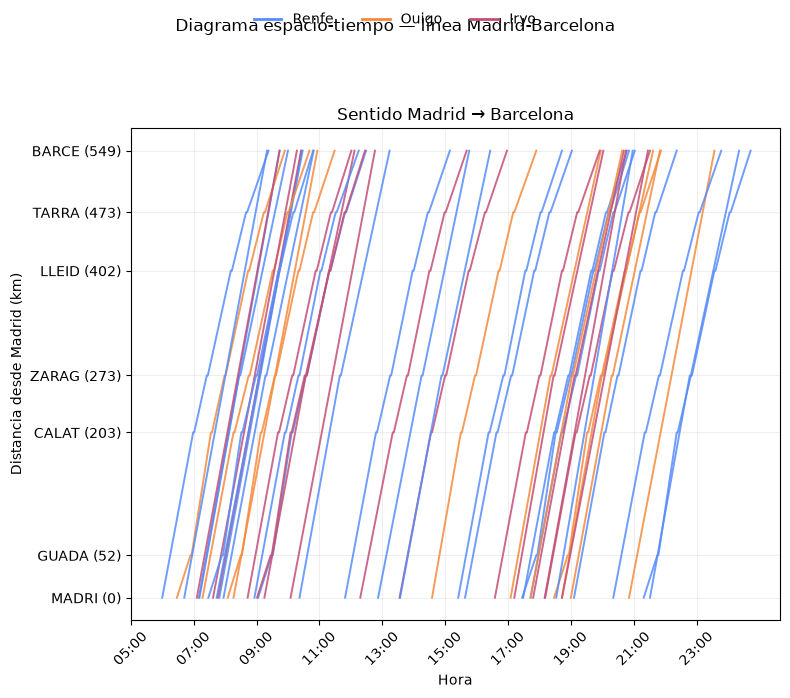

In [8]:
DIRECTIONS = list(CONFIG['directions'])
DIRECTION_TITLES = {'outbound': 'Sentido Madrid → Barcelona', 'inbound': 'Sentido Barcelona → Madrid'}
RU_COLORS = {
    ru['name']: color
    for ru, color in zip(CONFIG['rus'], plt.rcParams['axes.prop_cycle'].by_key()['color'])
}

fig, axes = plt.subplots(
    1, len(DIRECTIONS), figsize=(8 * len(DIRECTIONS), 7), sharey=True, squeeze=False
)

for ax, direction in zip(axes[0], DIRECTIONS):
    for svc in services:
        if svc['direction'] != direction:
            continue
        xs, ys = [], []
        for station, (arrival, departure) in svc['schedule'].items():
            xs.extend([arrival, departure])
            ys.extend([CUM_KM[station]] * 2)
        ax.plot(xs, ys, color=RU_COLORS[RU_NAME[svc['ru']]], lw=1.4, alpha=0.85)

    ticks = list(range(5 * 60, 23 * 60 + 1, 120))
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t // 60:02d}:{t % 60:02d}' for t in ticks], rotation=45)
    ax.set_xlabel('Hora')
    ax.set_title(DIRECTION_TITLES[direction])
    ax.grid(alpha=0.3)

axes[0][0].set_yticks([CUM_KM[s] for s in CORRIDOR])
axes[0][0].set_yticklabels([f"{STATIONS[s]['short_name']} ({CUM_KM[s]:.0f})" for s in CORRIDOR])
axes[0][0].set_ylabel('Distancia desde Madrid (km)')

handles = [Line2D([0], [0], color=color, lw=2, label=name) for name, color in RU_COLORS.items()]
fig.legend(handles=handles, loc='upper center', ncol=len(RU_COLORS), frameon=False)
fig.suptitle('Diagrama espacio-tiempo — línea Madrid-Barcelona', y=0.98)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

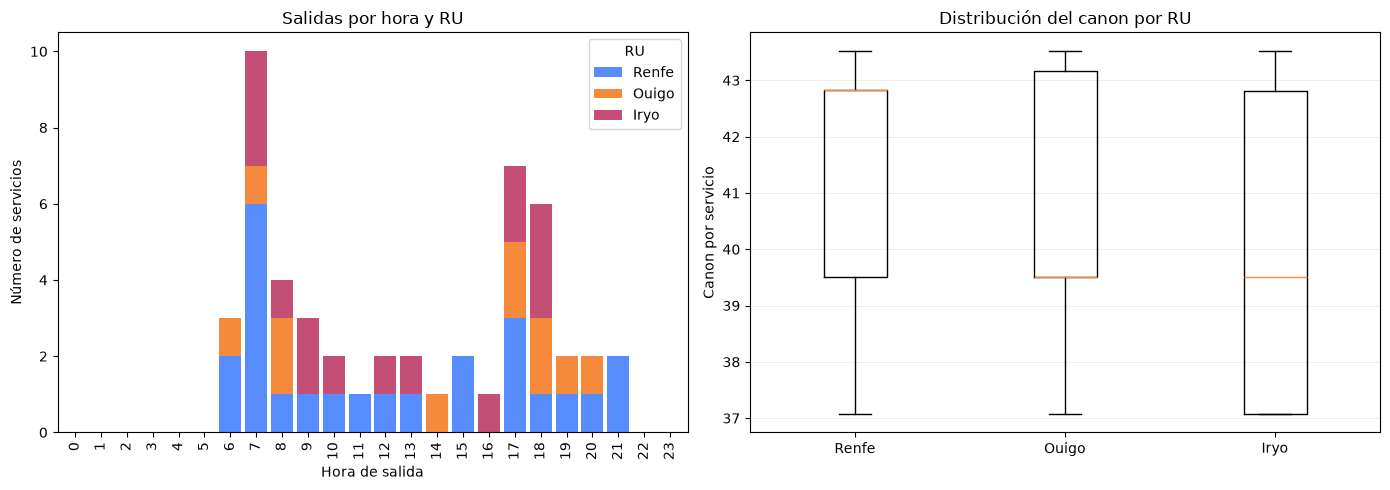

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

hours_df = services_df.assign(hour=services_df['departure_time'] // 60)
counts = hours_df.pivot_table(index='hour', columns='ru', values='id', aggfunc='count')
counts = counts.fillna(0).astype(int)
counts = counts.reindex(index=range(24), columns=list(RU_NAME), fill_value=0)
counts.columns = [RU_NAME[ru_id] for ru_id in counts.columns]
counts.plot(kind='bar', stacked=True, ax=ax1, color=[RU_COLORS[c] for c in counts.columns], width=0.85)
ax1.set_xlabel('Hora de salida')
ax1.set_ylabel('Número de servicios')
ax1.set_title('Salidas por hora y RU')
ax1.legend(title='RU')

canon_by_ru = revenue_df.assign(ru_name=revenue_df['ru'].map(RU_NAME))
ax2.boxplot(
    [canon_by_ru.loc[canon_by_ru['ru_name'] == name, 'canon'].to_numpy() for name in RU_COLORS],
    tick_labels=list(RU_COLORS),
)
ax2.set_ylabel('Canon por servicio')
ax2.set_title('Distribución del canon por RU')
ax2.grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

## Notas

- **Reproducibilidad**: con la misma `CONFIG` (misma `seed` incluida) se
  regeneran exactamente los mismos horarios y parámetros económicos; solo
  cambia la marca de tiempo `generated_at`.
- **Sentidos**: por defecto se generan solo servicios Madrid → Barcelona
  (`outbound`). Para incluir también el sentido Barcelona → Madrid, añade
  `'inbound'` con su probabilidad en `CONFIG['directions']`, por ejemplo
  `{'outbound': 0.5, 'inbound': 0.5}`; la validación y las figuras se adaptan
  automáticamente a los sentidos configurados.
- **Consumo**: los horarios se cargan con
  `Supply.from_yaml(path='data/synthetic/timetable.yaml')`. Los horarios de
  referencia en minutos desde medianoche (formato
  `{station: [llegada, salida]}`) se obtienen con
  `craft.scheduling.get_schedule_from_supply(path=...)`. `revenue.yaml` se
  carga con `yaml.safe_load` y se cruza con el supply por `services[*].id`.
  El archivo también es compatible con el resto de herramientas de robin,
  p. ej. `KernelPlotter.plot_marey_chart` como en el cuaderno `1.0`.
- **Compatibilidad**: las claves de `revenue.yaml` coinciden con el
  *revenue behavior* de `craft.revenue`, de modo que puede alimentar
  directamente a `RevenueCalculator` junto con los horarios de referencia.
- El directorio de salida `data/synthetic/` está ignorado por git, igual que
  el resto de resultados generados.